# Feasibility of PCA on the temporal features

The temporal features (177 stock, COE and macro series) have one value per month, and only **39 train months** (2021-01..2024-03) to learn from: more features than observations, and many of them near-copies of each other. PCA replaces them by a few uncorrelated components, which could make a model smaller and more stable. This notebook tests whether it does.

**The test.** The stage-1 model of the two-stage models predicts the *monthly mean rent* from the temporal features of the month. Here that prediction is made by one **Lasso regression** with a single fixed setting, fitted twice:

* on the **raw** 177 features, and
* on the **principal components** of the 177 features that hold 95% of their variance.

Both fits use exactly the same Lasso setting (`alpha = 0.001` on the standardised monthly rent), so the only difference is the input. Nothing is tuned: the 95% rule fixes the number of components, and the value of `alpha` is fixed in advance.

**The protocol.** The scaler and the PCA are fitted on the train months only; the validation months (2024-04..2025-03, 12 months) are only transformed. The models are scored once, on the validation months.

**Metrics.** *Level RMSE*: error of the predicted monthly level against the actual monthly mean rent of the 12 validation months. *Row RMSE*: the same predictions used as the prediction for every rental of the month, as the stage-1 error of the two-stage models is reported (it contains the spread of rents inside a month, about $650, which no month-level model can remove).
References: carrying the last train month forward, and extrapolating the straight-line trend of the train months.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)


def find_root(start):
    """final_report: the folder that holds data/feature_config_static.py."""
    for folder in (start, *start.parents):
        if (folder / 'data' / 'feature_config_static.py').exists():
            return folder
    raise FileNotFoundError('final_report/data/feature_config_static.py not found above ' + str(start))


ROOT = find_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / '02_modelling'))                 # nn_utils.py: the same data loading as the models
import nn_utils as nu                                          # noqa: E402

ALPHA = 0.001                                                  # the one Lasso setting, used for both inputs
VARIANCE_KEPT = 0.95                                           # the one PCA setting: components that hold 95% of the variance

INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb'
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 10.5, 'axes.titleweight': 'normal',
                     'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.7, 'axes.axisbelow': True,
                     'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'font.size': 9.5, 'legend.frameon': False, 'lines.linewidth': 2})

## 0. Data

`nn_utils.load_temporal` gives the 177 features of the 67 months, scaled by the data pipeline on the train months; the monthly target is the mean rent of the rentals approved in the month (train rentals for months 0..38, validation rentals for months 39..50).

In [2]:
temporal = nu.load_temporal()                                                      # 67 months x 177 features
train, _, _ = nu.load_static()
fit_rows, val_rows = (train['sample_type'] == 'train').to_numpy(), (train['sample_type'] == 'val').to_numpy()
TRAIN_MONTHS, VAL_MONTHS = list(range(0, nu.TRAIN_LAST + 1)), list(range(nu.TRAIN_LAST + 1, nu.VALIDATION_LAST + 1))
y_train = train[fit_rows].groupby('month')[nu.LABEL].mean().loc[TRAIN_MONTHS]
y_val = train[val_rows].groupby('month')[nu.LABEL].mean().loc[VAL_MONTHS]
Z_train, Z_val = temporal.loc[TRAIN_MONTHS], temporal.loc[VAL_MONTHS]
rent_val_rows, month_val_rows = train.loc[val_rows, nu.LABEL].to_numpy(), train.loc[val_rows, 'month'].to_numpy()
mu, sd = y_train.mean(), y_train.std()
print(f'{Z_train.shape[1]} features; {len(y_train)} train months, {len(y_val)} validation months; mean monthly rent ${y_train.mean():,.0f} (train), ${y_val.mean():,.0f} (validation)')


def evaluate(pred, train_pred=None):
    """Scores of a predicted monthly level (an array over the validation months)."""
    pred = pd.Series(np.asarray(pred), index=VAL_MONTHS)
    scores = {'val_level_rmse': nu.rmse(y_val, pred), 'val_row_rmse': nu.rmse(rent_val_rows, pred.loc[month_val_rows].to_numpy()), 'val_bias': float((pred - y_val).mean())}
    if train_pred is not None:
        scores = {'train_level_rmse': nu.rmse(y_train, train_pred), **scores}
    return scores


slope, intercept = np.polyfit(TRAIN_MONTHS, y_train, 1)
REFERENCES = {'carry the last train month forward': evaluate(np.full(len(VAL_MONTHS), y_train.iloc[-1])),
              'straight-line trend of the train months': evaluate(intercept + slope * np.array(VAL_MONTHS, dtype=float))}
display(pd.DataFrame(REFERENCES).T.round(1))

177 features; 39 train months, 12 validation months; mean monthly rent $2,604 (train), $3,126 (validation)


,val_level_rmse,val_row_rmse,val_bias
carry the last train month forward,38.4,659.9,-29.0
straight-line trend of the train months,383.7,761.5,368.4


## 1. The principal components

The PCA of the 39 train months (after standardising each feature). The first chart is the share of the variance of the 177 features that the first components hold, with the number of components that reach 95%; the second the correlation of each of the first 20 components with the monthly mean rent (a component that matters for the rent should correlate with it).
With 39 months the matrix has at most 38 components. The loadings table names the features that make up the first components.

components for 90% / 95% / 99% of the variance: 22 / 28 / 35; the PCA input below keeps the first 28 (95%)


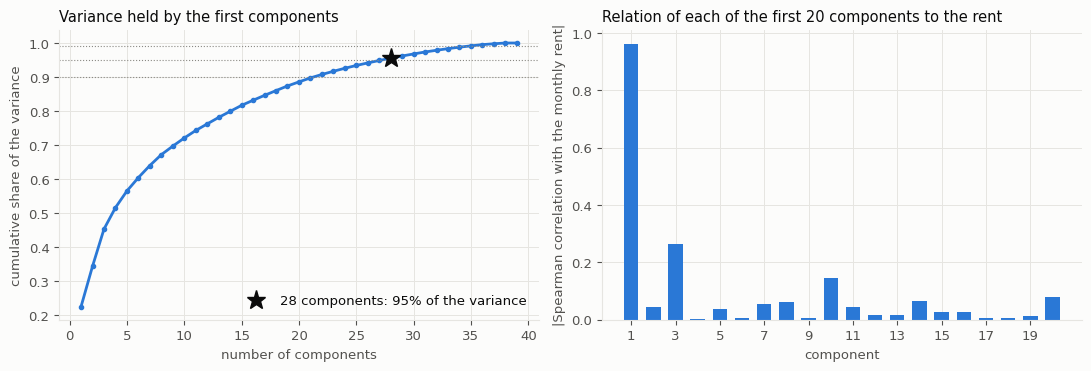

loading
PC1 (23% of the variance, rho with the rent -0.96) MACRO_UNEMPLOYMENT_SA_PCT                             0.150
                                                   stk_sembcorp_log_price_mean                          -0.149
                                                   stk_keppel_log_price_mean                            -0.149
                                                   stk_sea_limited_log_price_mean                        0.148
                                                   coe_a_quota_premium                                  -0.148
PC2 (12% of the variance, rho with the rent +0.05) coe_a_quota                                          -0.165
                                                   stk_hph_trust_hutchison_port_log_price_mean           0.161
                                                   stk_kenon_holdings_log_price_mean                     0.155
                                                   stk_suntec_reit_log_price_mean                        0.155
                                                   stk_pacific_century_regional_developments_log_p...    0.154
PC3 (11% of the variance, rho with the rent -0.27) stk_ascendas_reit_log_price_mean                     -0.169
                                                   stk_sats_mom_return                                  -0.151
                                                   stk_keppel_reit_mom_return                           -0.142
                                                   stk_haw_par_mom_return                               -0.139
                                                   stk_st_engineering_mom_return                        -0.139

In [3]:
scaler = StandardScaler().fit(Z_train)
pca_full = PCA(random_state=0).fit(scaler.transform(Z_train))
cum = np.cumsum(pca_full.explained_variance_ratio_)
K = int(np.searchsorted(cum, VARIANCE_KEPT)) + 1                                    # components that hold 95% of the variance
scores = pca_full.transform(scaler.transform(Z_train))
rent_corr = np.array([stats.spearmanr(scores[:, i], y_train)[0] for i in range(scores.shape[1])])
print('components for 90% / 95% / 99% of the variance: ' + ' / '.join(str(int(np.searchsorted(cum, q)) + 1) for q in (0.90, 0.95, 0.99)) + f'; the PCA input below keeps the first {K} (95%)')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(np.arange(1, len(cum) + 1), cum, color=BLUE, marker='o', ms=3)
for q in (0.90, 0.95, 0.99):
    ax.axhline(q, color=MUTED, lw=0.8, ls=':')
ax.plot([K], [cum[K - 1]], marker='*', ms=14, color=INK, ls='', label=f'{K} components: 95% of the variance')
ax.legend(loc='lower right')
ax.set_xlabel('number of components')
ax.set_ylabel('cumulative share of the variance')
ax.set_title('Variance held by the first components')
ax = axes[1]
ax.bar(np.arange(1, 21), np.abs(rent_corr[:20]), color=BLUE, width=0.65)
ax.set_xlabel('component')
ax.set_ylabel('|Spearman correlation with the monthly rent|')
ax.set_title('Relation of each of the first 20 components to the rent')
ax.set_xticks(range(1, 21, 2))
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca_full.components_[:3].T, index=Z_train.columns, columns=['PC1', 'PC2', 'PC3'])
display(pd.concat({f'PC{i + 1} ({pca_full.explained_variance_ratio_[i]:.0%} of the variance, rho with the rent {rent_corr[i]:+.2f})': loadings[f'PC{i + 1}'].reindex(loadings[f'PC{i + 1}'].abs().sort_values(ascending=False).index).head(5).round(3).to_frame('loading')
                   for i in range(3)}, axis=0))

## 2. One Lasso on the raw features, one on the components

The same Lasso (`alpha = 0.001` on the standardised monthly rent) is fitted on the 39 train months with the 177 raw features and with the first components that hold 95% of their variance (the components are used as they come out of the PCA).
Both are then used to predict the 12 validation months.

In [4]:
y_std = ((y_train - mu) / sd).to_numpy()
pca = PCA(n_components=K, random_state=0).fit(scaler.transform(Z_train))
inputs = {f'raw ({Z_train.shape[1]} features)': (scaler.transform(Z_train), scaler.transform(Z_val)),
          f'PCA ({K} components, 95% of the variance)': (pca.transform(scaler.transform(Z_train)), pca.transform(scaler.transform(Z_val)))}
rows, predictions = [], {}
for name, (A_train, A_val) in inputs.items():
    lasso = Lasso(alpha=ALPHA, max_iter=200_000).fit(A_train, y_std)
    pred_val, pred_train = lasso.predict(A_val) * sd + mu, lasso.predict(A_train) * sd + mu
    predictions[name] = pred_val
    rows.append({'inputs': name, 'n_inputs': A_train.shape[1], 'nonzero_coefficients': int((lasso.coef_ != 0).sum()), **evaluate(pred_val, pred_train)})
results = pd.DataFrame(rows).set_index('inputs')
display(results.round(1))
raw_row, pca_row = results.iloc[0], results.iloc[1]
print(f'validation level RMSE: ${raw_row["val_level_rmse"]:,.1f} on the raw features, ${pca_row["val_level_rmse"]:,.1f} on the {K} components; '
      f'row RMSE ${raw_row["val_row_rmse"]:,.1f} against ${pca_row["val_row_rmse"]:,.1f}; carrying the last month forward: ${REFERENCES["carry the last train month forward"]["val_level_rmse"]:,.1f}')

,n_inputs,nonzero_coefficients,train_level_rmse,val_level_rmse,val_row_rmse,val_bias
inputs,,,,,,
raw (177 features),177,38,2.4,39.9,659.9,3.3
"PCA (28 components, 95% of the variance)",28,28,19.3,115.5,668.6,-107.6


validation level RMSE: $39.9 on the raw features, $115.5 on the 28 components; row RMSE $659.9 against $668.6; carrying the last month forward: $38.4


### 2.1 Predicted levels in the validation months

The monthly mean rent of the last 12 train months and of the 12 validation months, and the level predicted for the validation months by the carry-forward reference, the Lasso on the raw features and the Lasso on the components.

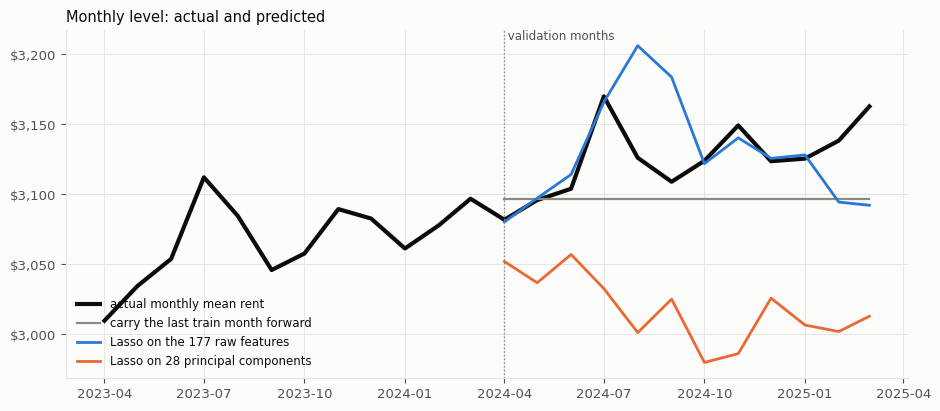

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
months = TRAIN_MONTHS[-12:] + VAL_MONTHS
dates = pd.to_datetime([f'{2021 + m // 12}-{m % 12 + 1:02d}-01' for m in months])
actual = pd.concat([y_train.iloc[-12:], y_val])
ax.plot(dates, actual, color=INK, lw=3, label='actual monthly mean rent')
vdates = dates[12:]
ax.plot(vdates, np.full(len(VAL_MONTHS), y_train.iloc[-1]), color=MUTED, lw=1.6, label='carry the last train month forward')
names = list(predictions)
ax.plot(vdates, predictions[names[0]], color=BLUE, label='Lasso on the 177 raw features')
ax.plot(vdates, predictions[names[1]], color=ORANGE, label=f'Lasso on {K} principal components')
ax.axvline(dates[12], color=MUTED, ls=':', lw=1)
ax.text(dates[12], ax.get_ylim()[1], ' validation months', va='top', fontsize=8.5, color=INK2)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Monthly level: actual and predicted')
ax.legend(loc='lower left', fontsize=8.5)
plt.tight_layout()
plt.show()

### 2.2 Performance for different numbers of components

The same Lasso (`alpha = 0.001`, nothing else changed) fitted on the first k principal components, for k from 1 to the 38 components that exist, against the 177 raw features. The components are nested: the first k components of the PCA above are the input for k.
`variance_held` is the share of the variance of the 177 features that the k components hold; the rows for 90%, 95% (the setting used above) and 99% of the variance are marked. The validation columns are scored on the 12 validation months; the train column is the error on the 39 months the model was fitted on.
`level_rmse_vs_raw_pct` is the increase of the validation level RMSE over the raw-feature model (0 would be as good as the raw features, +100% twice the error; a negative value is better).

In [6]:
KS = [1, 2, 3, 5, 10, 15, 22, 28, 35, 38]
NOTES = {22: '90% of the variance', 28: '95% of the variance (used above)', 35: '99% of the variance', 38: 'all components'}
train_scores, val_scores = pca_full.transform(scaler.transform(Z_train)), pca_full.transform(scaler.transform(Z_val))

raw_lasso = Lasso(alpha=ALPHA, max_iter=200_000).fit(scaler.transform(Z_train), y_std)
rows = [{'inputs': f'raw ({Z_train.shape[1]} features)', 'k': Z_train.shape[1], 'variance_held': 1.0, 'nonzero_coefficients': int((raw_lasso.coef_ != 0).sum()),
         **evaluate(raw_lasso.predict(scaler.transform(Z_val)) * sd + mu, raw_lasso.predict(scaler.transform(Z_train)) * sd + mu), 'note': 'raw features'}]
for k in KS:
    lasso = Lasso(alpha=ALPHA, max_iter=200_000).fit(train_scores[:, :k], y_std)
    rows.append({'inputs': f'PCA, k = {k}', 'k': k, 'variance_held': cum[k - 1], 'nonzero_coefficients': int((lasso.coef_ != 0).sum()),
                 **evaluate(lasso.predict(val_scores[:, :k]) * sd + mu, lasso.predict(train_scores[:, :k]) * sd + mu), 'note': NOTES.get(k, '')})
by_k = pd.DataFrame(rows).set_index('inputs')
carry = REFERENCES['carry the last train month forward']
table = pd.concat([by_k, pd.DataFrame([{**carry, 'note': 'reference'}], index=['carry the last train month forward'])])
table['level_rmse_vs_raw_pct'] = 100 * (table['val_level_rmse'] / by_k.iloc[0]['val_level_rmse'] - 1)           # increase of the validation level RMSE over the raw-feature model
columns = ['variance_held', 'nonzero_coefficients', 'train_level_rmse', 'val_level_rmse', 'level_rmse_vs_raw_pct', 'val_row_rmse', 'val_bias', 'note']
display(table[columns].round({'variance_held': 3, 'train_level_rmse': 1, 'val_level_rmse': 1, 'level_rmse_vs_raw_pct': 1, 'val_row_rmse': 1, 'val_bias': 1}))
best = by_k.iloc[1:]['val_level_rmse'].idxmin()
print(f'lowest validation level RMSE among the PCA inputs: {best} (${by_k.loc[best, "val_level_rmse"]:,.1f}); raw features ${by_k.iloc[0]["val_level_rmse"]:,.1f}; carry-forward ${carry["val_level_rmse"]:,.1f}')

,variance_held,nonzero_coefficients,train_level_rmse,val_level_rmse,level_rmse_vs_raw_pct,val_row_rmse,val_bias,note
raw (177 features),1.000,38.0,2.4,39.9,0.0,659.9,3.3,raw features
"PCA, k = 1",0.225,1.0,95.2,93.7,134.8,665.3,-85.9,
"PCA, k = 2",0.344,2.0,94.6,96.8,142.6,665.8,-89.9,
"PCA, k = 3",0.453,3.0,68.4,40.2,0.8,659.9,12.2,
"PCA, k = 5",0.565,5.0,52.5,80.6,102.0,663.6,-68.8,
"PCA, k = 10",0.721,10.0,42.6,118.8,197.7,669.2,-112.7,
"PCA, k = 15",0.817,15.0,36.1,108.8,172.7,667.7,-103.1,
"PCA, k = 22",0.908,22.0,26.9,114.5,187.1,668.6,-105.6,90% of the variance
"PCA, k = 28",0.955,28.0,19.3,115.5,189.4,668.6,-107.6,95% of the variance (used above)
"PCA, k = 35",0.992,35.0,6.7,82.4,106.6,663.8,-76.7,99% of the variance


lowest validation level RMSE among the PCA inputs: PCA, k = 3 ($40.2); raw features $39.9; carry-forward $38.4


# Findings

From the run stored in this notebook: one Lasso setting (`alpha = 0.001`), fitted on the 39 train months and scored on the 12 validation months.

* **The features compress slowly, and the rent is not in the top components.** 22, 28 and 35 components hold 90%, 95% and 99% of the variance (at most 38 exist). The first component (23% of the variance, made of stock prices, the COE premium and unemployment, all trending) correlates -0.96 with the monthly mean rent: it is the shared trend. Apart from it, the components relate weakly to the rent (PC3 -0.27, almost all others below 0.15).
* **The raw features forecast better.** Level RMSE on the validation months: $39.9 for the Lasso on the 177 raw features (it keeps 38 of them), $115.5 for the Lasso on the 28 components that hold 95% of the variance. The components are also biased: they predict $108 too low on average, against +$3 for the raw features, and the predicted level stays below the actual one for all 12 months. The RMSE of the rentals (about $660 for all of them) moves little, from $659.9 to $668.6, because it is dominated by the spread of rents inside a month.
* **No number of components matches the raw features reliably (Section 2.2).** With the same Lasso, the validation level RMSE is $93.7 and $96.8 for 1 and 2 components, $80.6 for 5, between $108.8 and $118.8 for 10 to 28 components, and $82.4 and $82.1 for 35 and 38 components, against $39.9 on the raw features: 102% to 198% higher for every number of components except 3 (+0.8%). Only 3 components come close ($40.2), but their error on the train months is $68 against $2.4 for the raw features and their neighbours (2 and 5 components) are far worse, so this looks like chance in a nearly flat validation year, not a better input.
* **The raw-feature model is as good as carrying the last month forward** ($38.4), which the validation year (nearly flat) makes hard to beat; the components do not get there.

**Verdict.** PCA does not improve the temporal features for the Lasso stage-1 model: with the same setting, the model on the raw features forecasts the validation months about three times better, and it already selects a small subset (38 of 177) by itself.
Limits: one fixed `alpha` and one number of components (the 95% rule), neither tuned; only the Lasso was tested (not the temporal network); 39 train months and 12 validation months make the comparison noisy.